In [5]:
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import glob

In [6]:
#metodo para mostrar brillo y oscuro
def mostrar_dos_imagenes(brillo, oscuro, titulos=("Brillo", "Oscuro")):
    imagenes = [brillo, oscuro]
    fig, axes = plt.subplots(1,2, figsize=(10,12))
    for(ax, img, titulo) in zip(axes, imagenes, titulos):
        ax.imshow(img)
        ax.set_title(titulo)
        ax.axis('off')
        plt.tight_layout()
    plt.show()

In [7]:
#metodo para mostrar canales greyscale
def mostrar_canales(img, titulos=("Canal 1", "Canal 2", "Canal 3")):
    A,B,C = cv.split(img)
    canales = [A,B,C]

    fig, axes = plt.subplots(1,3,figsize=(5,6))
    for(ax, img, titulo) in zip(axes, canales, titulos):
        ax.imshow(img, cmap = 'gray')
        ax.set_title(titulo)
        ax.axis('off')
        plt.tight_layout()
    plt.show()
   

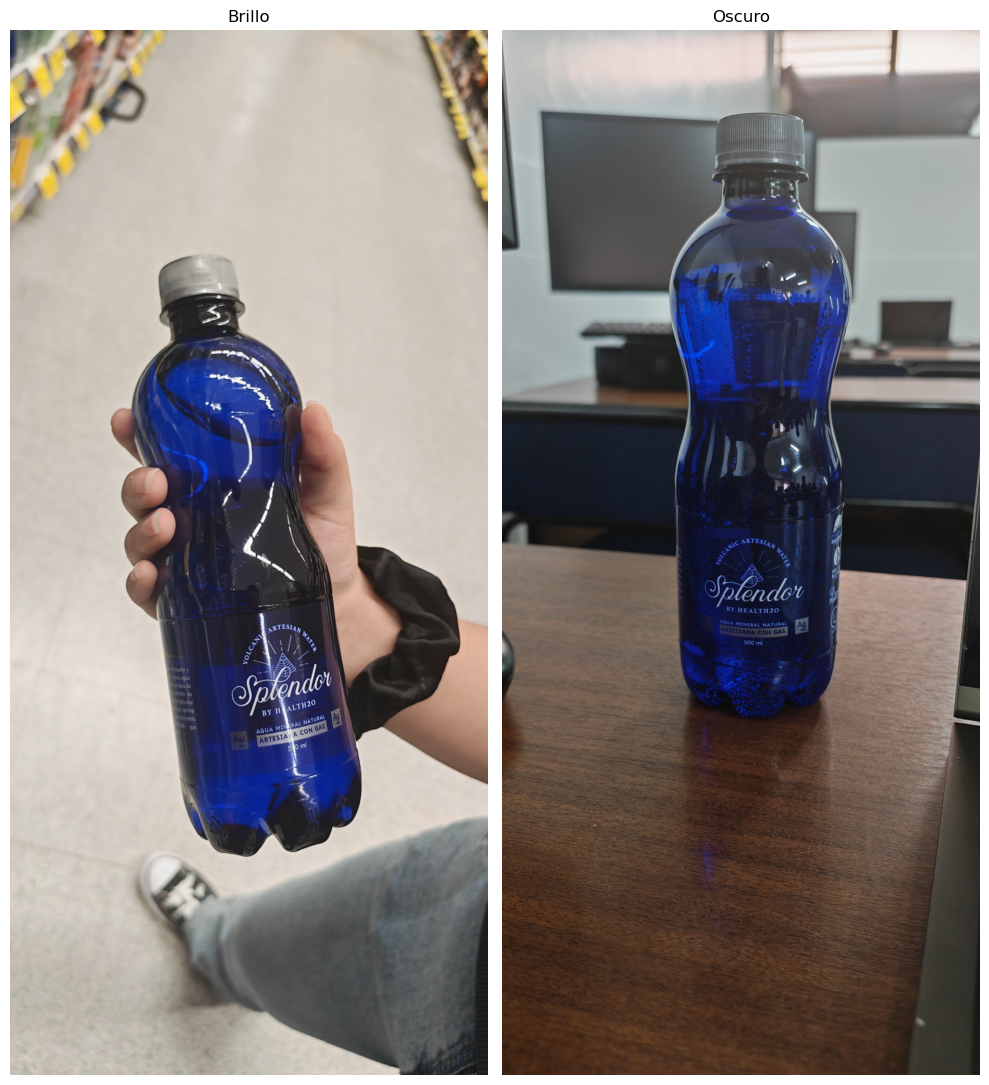

In [8]:
bright = cv.imread('../data/raw/agua/agua_brillo.jpg')
dark = cv.imread('../data/raw/agua/agua_oscuro.jpg')
bright_RGB = cv.cvtColor(bright, cv.COLOR_BGR2RGB)
dark_RGB = cv.cvtColor(dark,cv.COLOR_BGR2RGB)
mostrar_dos_imagenes(bright_RGB, dark_RGB)

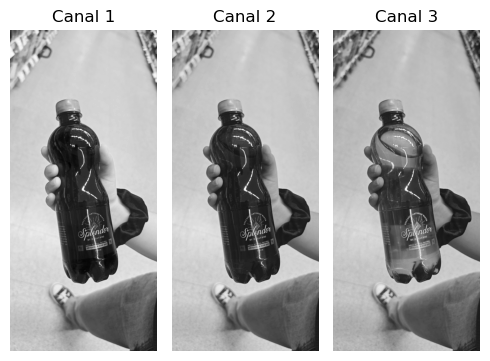

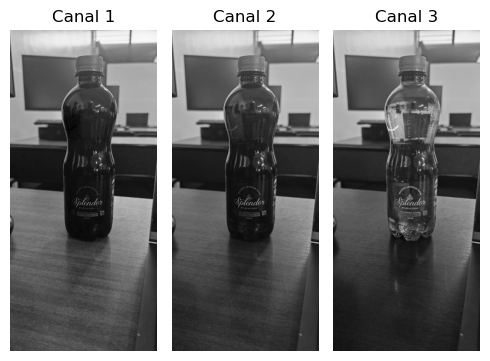

In [9]:
mostrar_canales(bright_RGB)
mostrar_canales(dark_RGB)

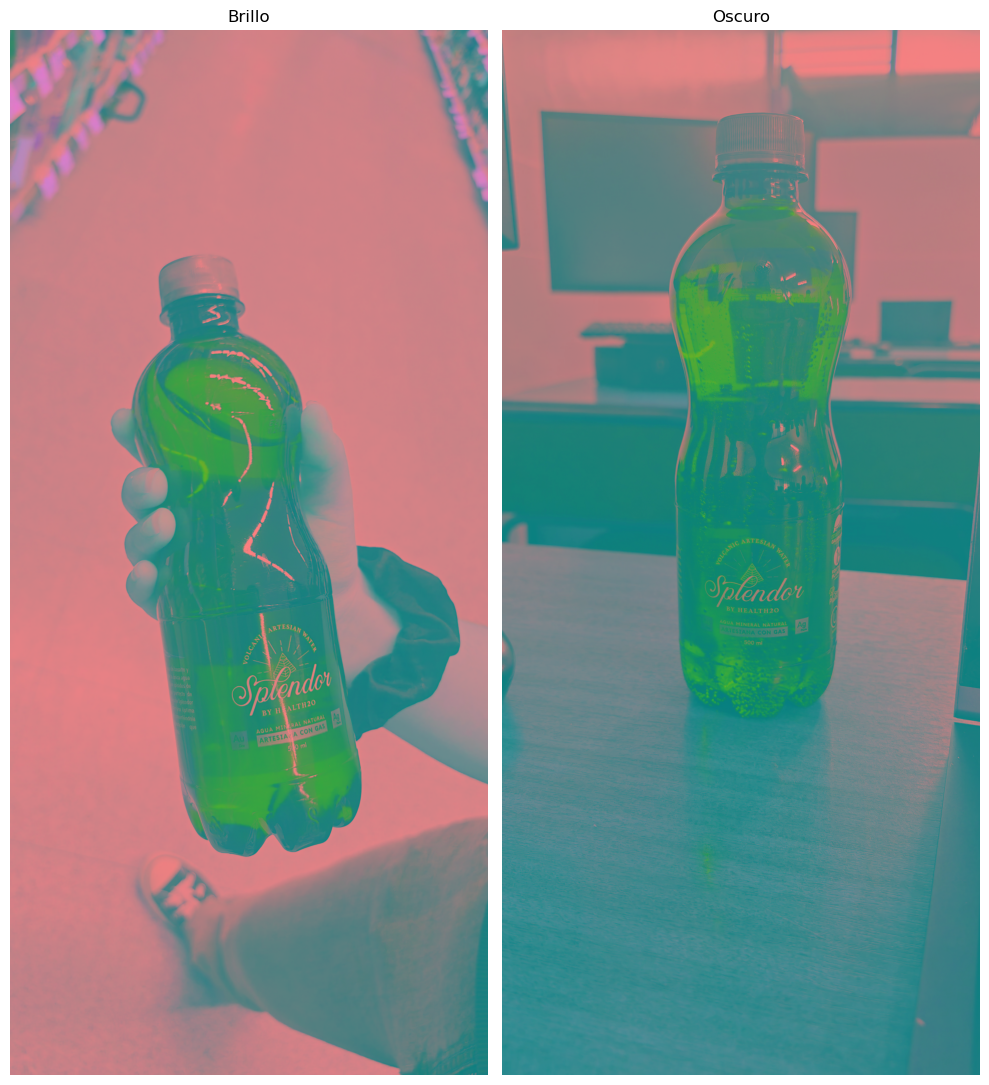

In [10]:
brightLAB = cv.cvtColor(bright, cv.COLOR_BGR2LAB)
darkLAB = cv.cvtColor(dark, cv.COLOR_BGR2LAB)
mostrar_dos_imagenes(brightLAB, darkLAB)

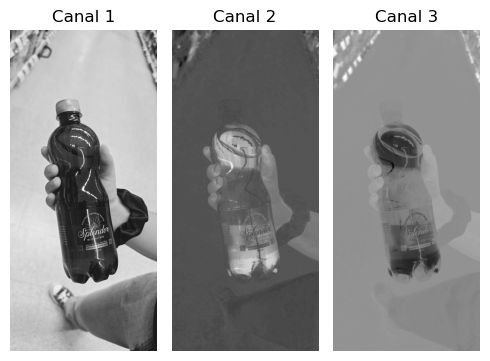

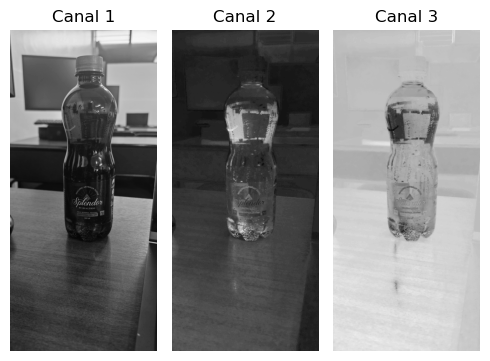

In [11]:
mostrar_canales(brightLAB)
mostrar_canales(darkLAB)

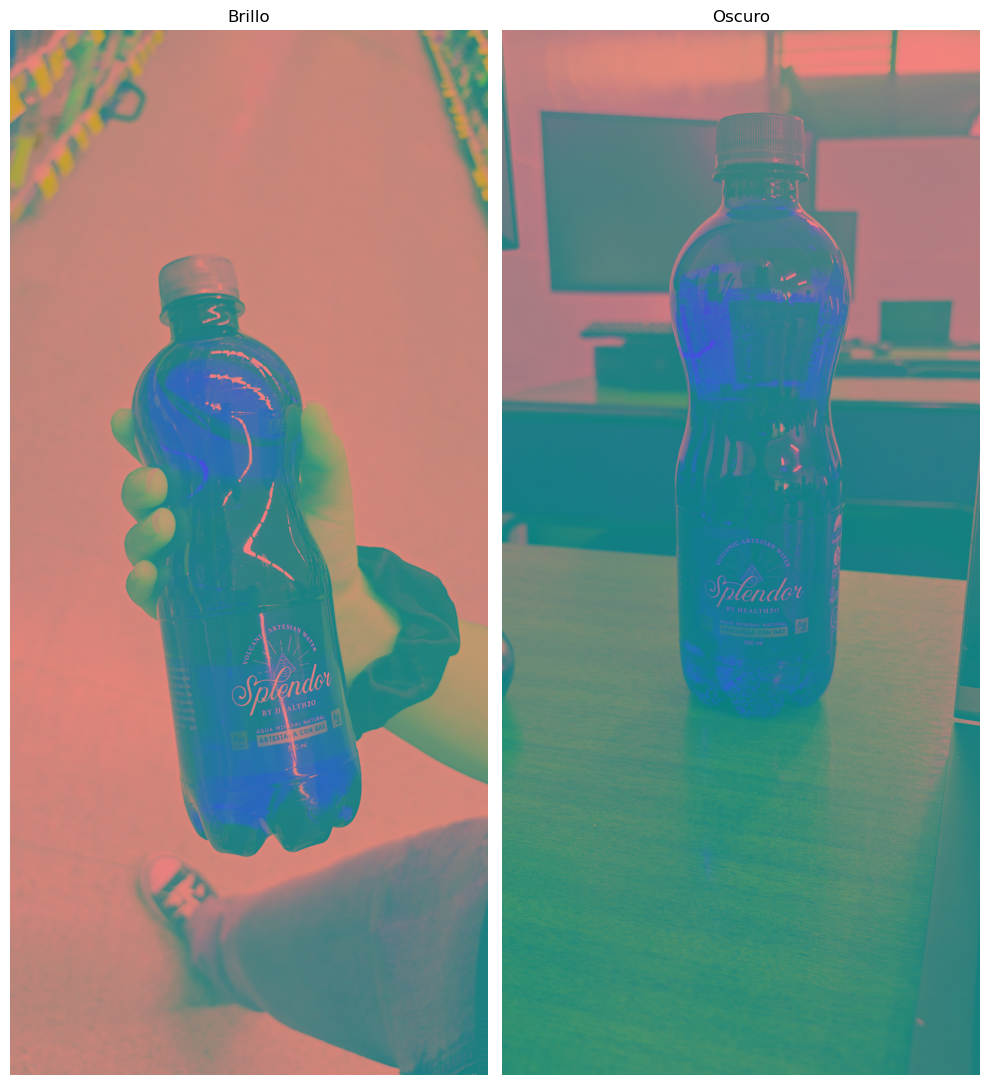

In [12]:
brightYCB = cv.cvtColor(bright, cv.COLOR_BGR2YCrCb)
darkYCB = cv.cvtColor(dark, cv.COLOR_BGR2YCrCb)
mostrar_dos_imagenes(brightYCB,darkYCB)

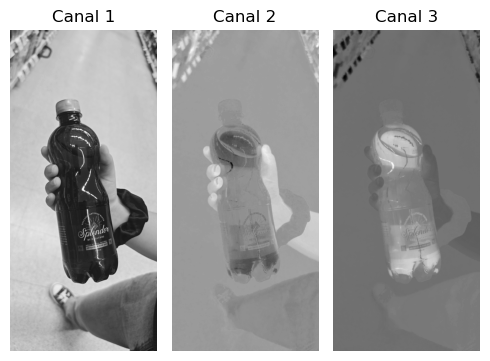

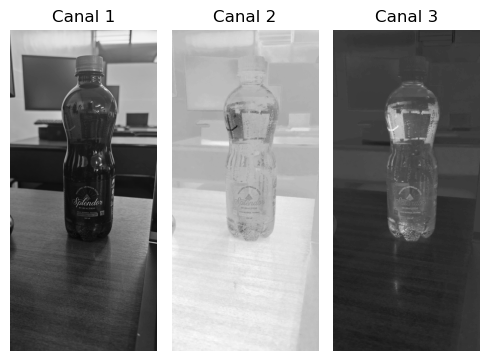

In [13]:
mostrar_canales(brightYCB)
mostrar_canales(darkYCB)

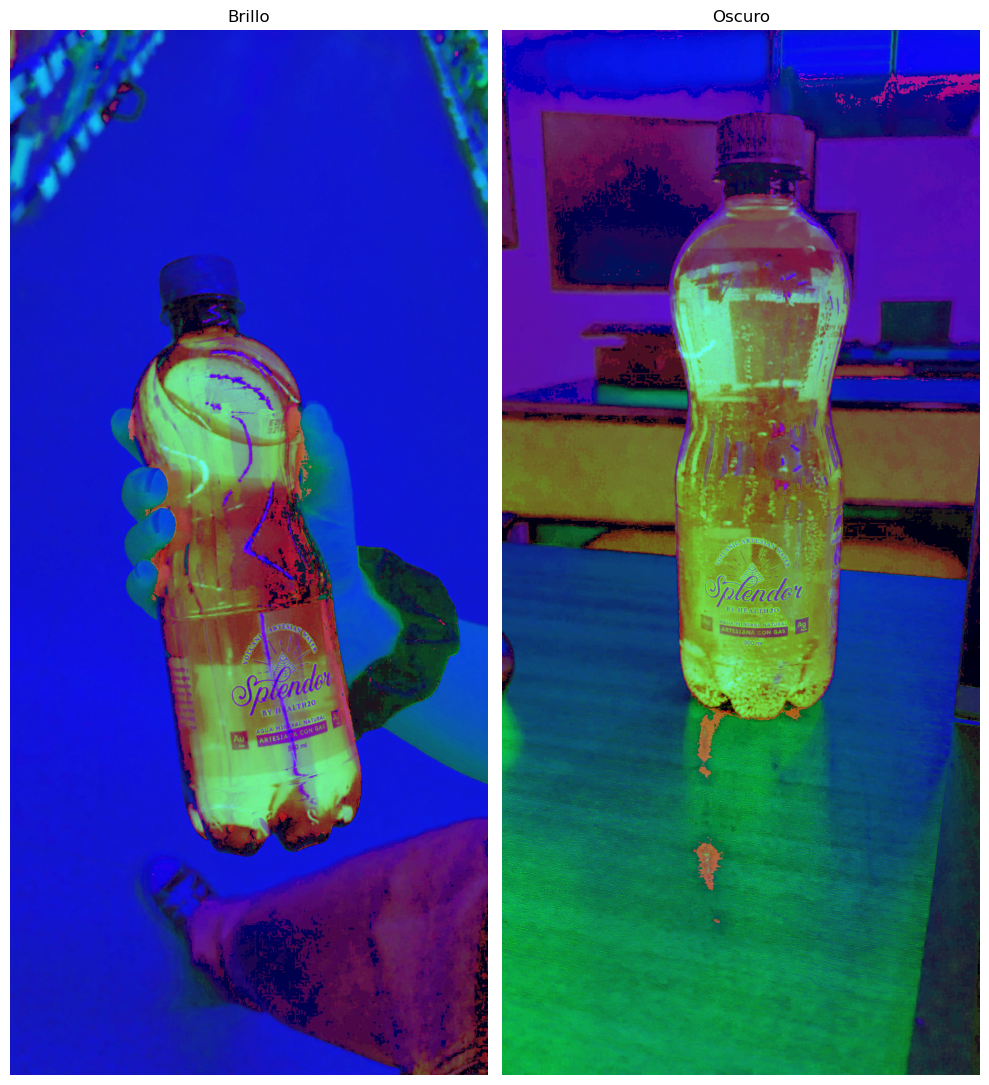

In [14]:
brightHSV = cv.cvtColor(bright, cv.COLOR_BGR2HSV)
darkHSV = cv.cvtColor(dark, cv.COLOR_BGR2HSV)
mostrar_dos_imagenes(brightHSV,darkHSV)

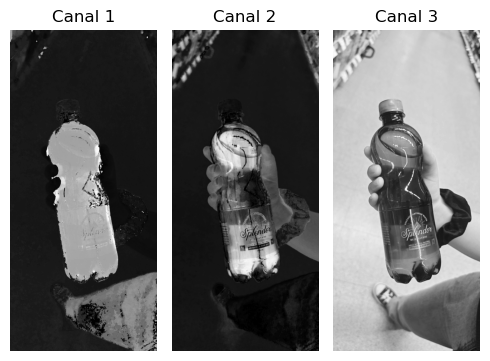

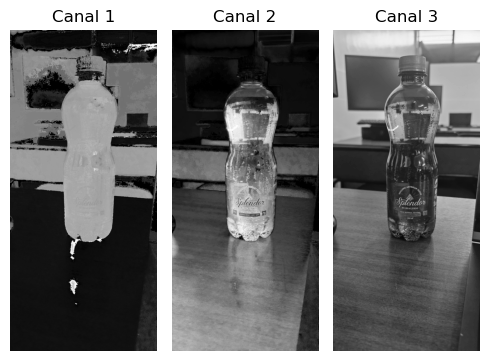

In [15]:
mostrar_canales(brightHSV)
mostrar_canales(darkHSV)

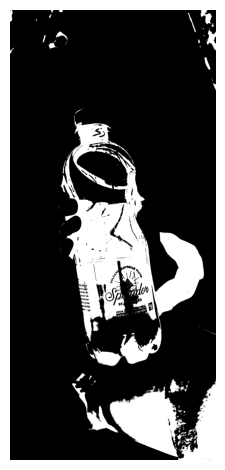

In [16]:
bgr = [46, 43, 50]
thresh = 45

minBGR = np.array([bgr[0] - thresh, bgr[1] - thresh, bgr[2] - thresh])
maxBGR = np.array([bgr[0] + thresh, bgr[1] + thresh, bgr[2] + thresh])

maskBGR = cv.inRange(bright,minBGR,maxBGR)
resultBGR = cv.bitwise_and(bright, bright, mask = maskBGR)
#resultRGB = cv.bitwise_and(bright,bright,mask=maskRGB)

plt.axis('off')
plt.imshow(maskBGR, cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()


In [17]:
image_paths = glob.glob("../data/raw/agua/samples/*.jpg")
print(image_paths)
image_paths2 = glob.glob("../data/raw/agua/samplesSmall/*.jpg")
print(image_paths)

['../data/raw/agua/samples\\agua_sample1.jpg', '../data/raw/agua/samples\\agua_sample2.jpg', '../data/raw/agua/samples\\agua_sample3.jpg', '../data/raw/agua/samples\\agua_sample4.jpg', '../data/raw/agua/samples\\agua_sample5.jpg']
['../data/raw/agua/samples\\agua_sample1.jpg', '../data/raw/agua/samples\\agua_sample2.jpg', '../data/raw/agua/samples\\agua_sample3.jpg', '../data/raw/agua/samples\\agua_sample4.jpg', '../data/raw/agua/samples\\agua_sample5.jpg']


(0.0, 255.0)

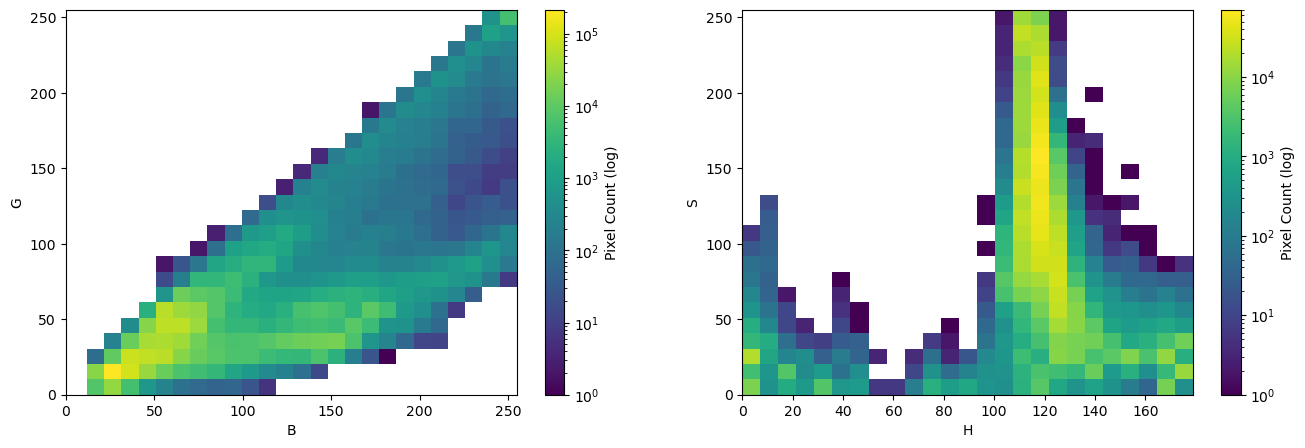

In [18]:
B = np.array([])
G = np.array([])
R = np.array([])

H = np.array([])
S = np.array([])
V = np.array([])

for fi in  image_paths: 
    mimami = cv.imread(fi)
    im2 = cv.cvtColor(mimami, cv.COLOR_BGR2HSV)
    #esto para Rgb
    b = mimami[:,:,0]
    b = b.reshape(b.shape[0]*b.shape[1])
    g = mimami[:,:,1]
    g = g.reshape(g.shape[0]*g.shape[1])
    r = mimami[:,:,2]
    r = r.reshape(r.shape[0]*r.shape[1])
    B = np.append(B,b)
    G = np.append(G,g)
    R = np.append(R,r)
    #esto para hsv
    h = im2[:,:,0]
    h = h.reshape(h.shape[0]*h.shape[1])
    s = im2[:,:,1]
    s = s.reshape(s.shape[0]*s.shape[1])
    v = im2[:,:,2]
    v = v.reshape(v.shape[0]*v.shape[1])
    H = np.append(H,h)
    S = np.append(S,s)
    V = np.append(V,v)

plt.figure(figsize=(16,5))
nbins = 25
plt.subplot(1,2,1)
plt.hist2d(B, G, bins=nbins, norm=LogNorm())
plt.colorbar(label='Pixel Count (log)')
plt.xlabel('B')
plt.ylabel('G')
plt.xlim([0,255])
plt.ylim([0,255])

plt.subplot(1,2,2)
plt.hist2d(H, S, bins=nbins, norm=LogNorm())
plt.colorbar(label='Pixel Count (log)')
plt.xlabel('H')
plt.ylabel('S')
plt.xlim([0,179])
plt.ylim([0,255])

In [19]:
def analyze_color_space(
    image_paths,
    color_code=None,
    names=("Ch 0", "Ch 1", "Ch 2"),
    limits=((0, 255), (0, 255), (0, 255)),
    sample_step=5,
    nbins=25,
):
    ch0_list, ch1_list, ch2_list = [], [], []

    for fi in image_paths:
        img = cv.imread(fi)
        if img is None:
            continue

        
        img = img[::sample_step, ::sample_step]
        if color_code is not None:
            img = cv.cvtColor(img, color_code)

        
        ch0_list.append(img[:, :, 0].ravel())
        ch1_list.append(img[:, :, 1].ravel())
        ch2_list.append(img[:, :, 2].ravel())

    c0 = np.concatenate(ch0_list)
    c1 = np.concatenate(ch1_list)
    c2 = np.concatenate(ch2_list)

    pairs = [
        (c0, c1, names[0], names[1], limits[0], limits[1]),
        (c0, c2, names[0], names[2], limits[0], limits[2]),
        (c1, c2, names[1], names[2], limits[1], limits[2]),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, (x, y, xlabel, ylabel, xlim, ylim) in zip(axes, pairs):
        h = ax.hist2d(x, y, bins=nbins, norm=LogNorm())
        fig.colorbar(h[3], ax=ax, label="Counts (log)")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_title(f"{xlabel} vs {ylabel}")

    plt.tight_layout()
    plt.show()

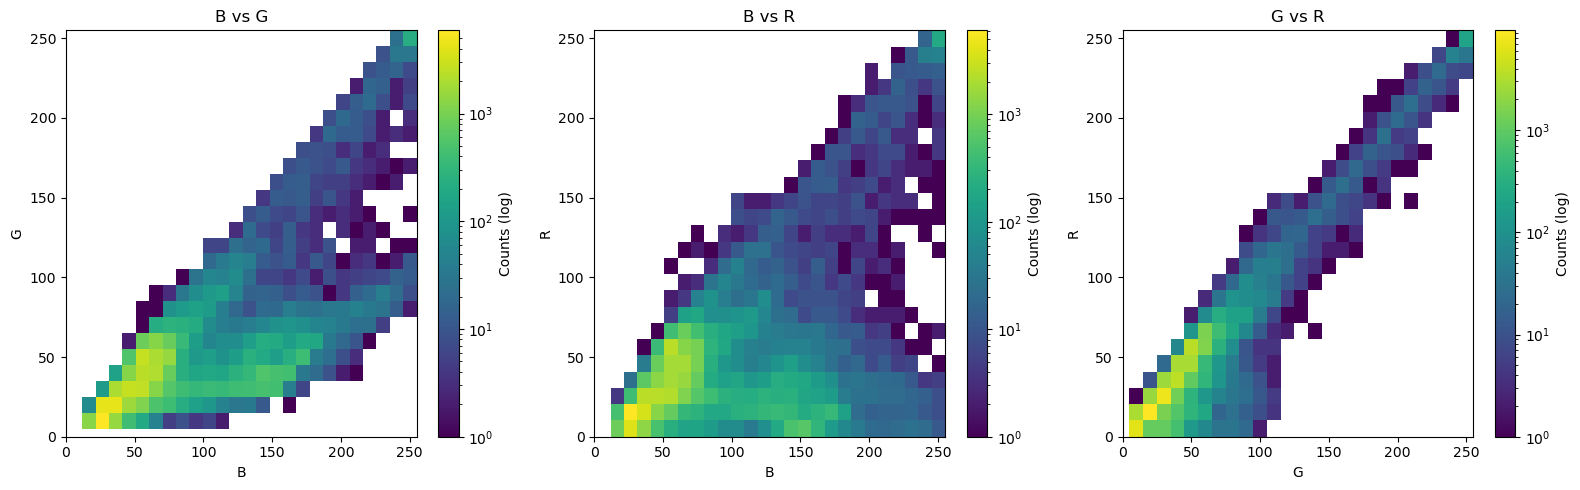

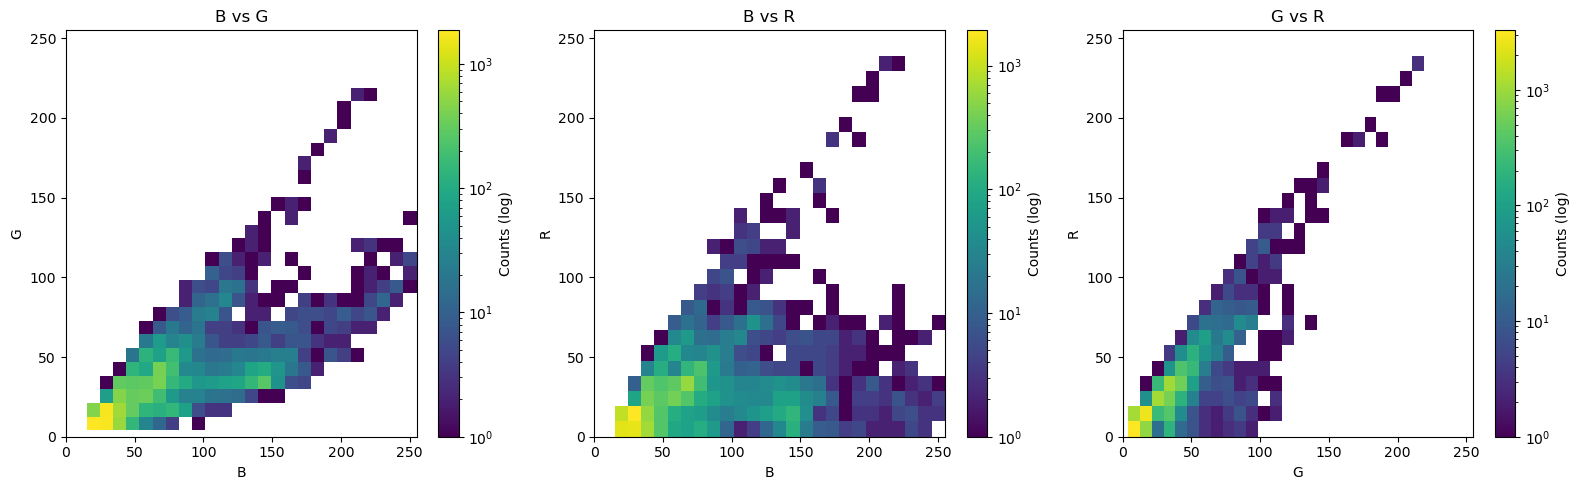

In [20]:
analyze_color_space(
    image_paths,
    color_code=None,  # OpenCV reads BGR directly
    names=("B", "G", "R"),
    limits=((0, 255), (0, 255), (0, 255)),
)
analyze_color_space(
    image_paths2,
    color_code=None,  # OpenCV reads BGR directly
    names=("B", "G", "R"),
    limits=((0, 255), (0, 255), (0, 255)),
)

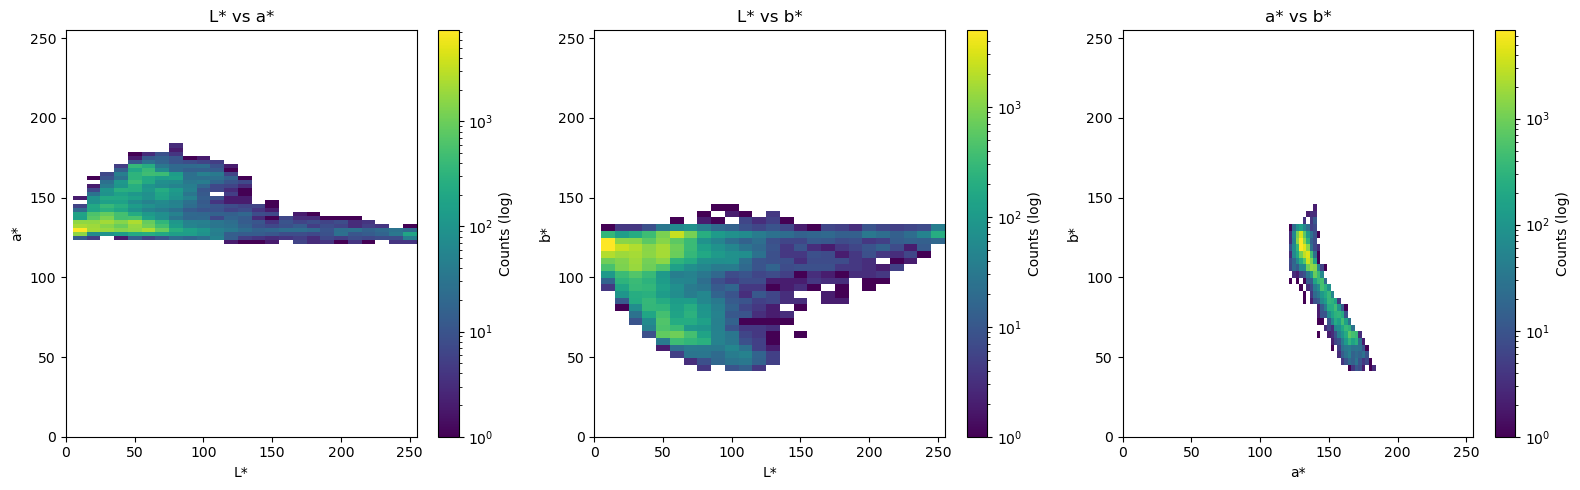

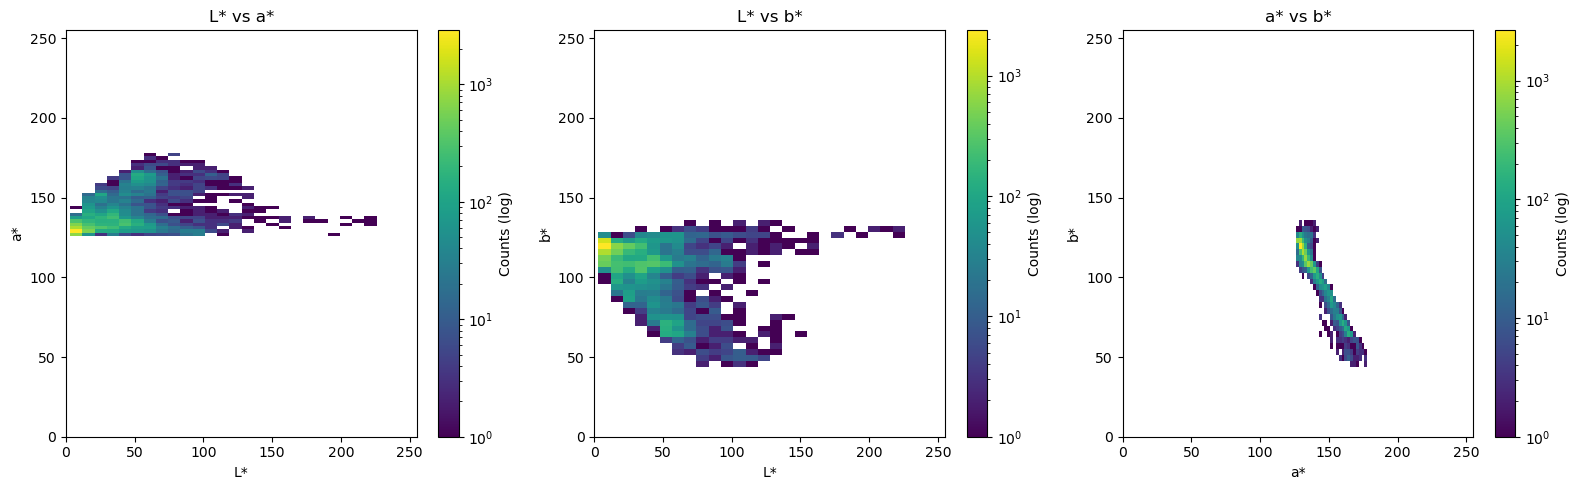

In [21]:
analyze_color_space(
    image_paths,
    color_code=cv.COLOR_BGR2LAB,
    names=("L*", "a*", "b*"),
    limits=((0, 255), (0, 255), (0, 255)),
)
analyze_color_space(
    image_paths2,
    color_code=cv.COLOR_BGR2LAB,
    names=("L*", "a*", "b*"),
    limits=((0, 255), (0, 255), (0, 255)),
)

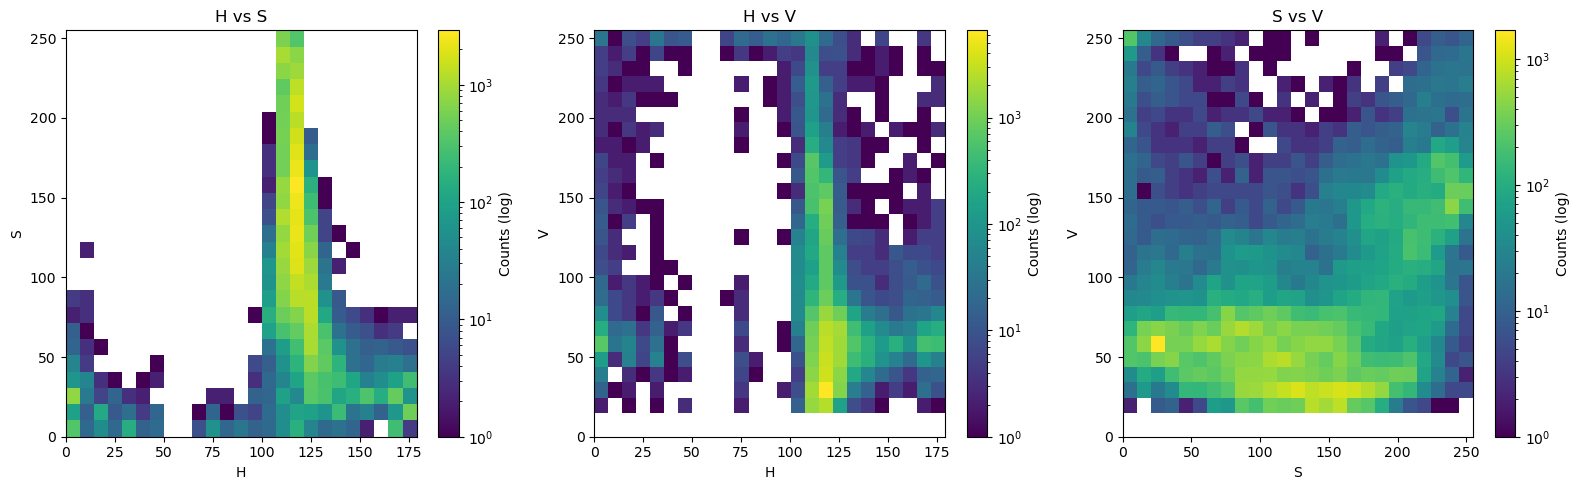

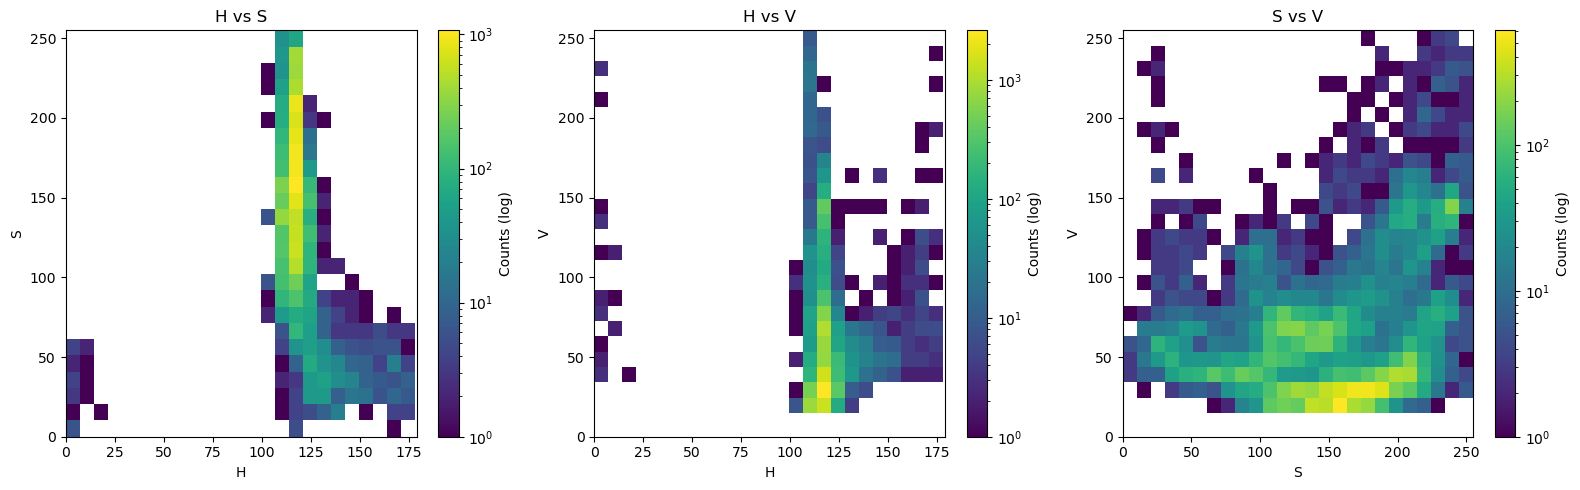

In [22]:
analyze_color_space(
    image_paths,
    color_code=cv.COLOR_BGR2HSV,
    names=("H", "S", "V"),
    limits=((0, 179), (0, 255), (0, 255)),  # H max is 179 in OpenCV
)
analyze_color_space(
    image_paths2,
    color_code=cv.COLOR_BGR2HSV,
    names=("H", "S", "V"),
    limits=((0, 179), (0, 255), (0, 255)),  # H max is 179 in OpenCV
)


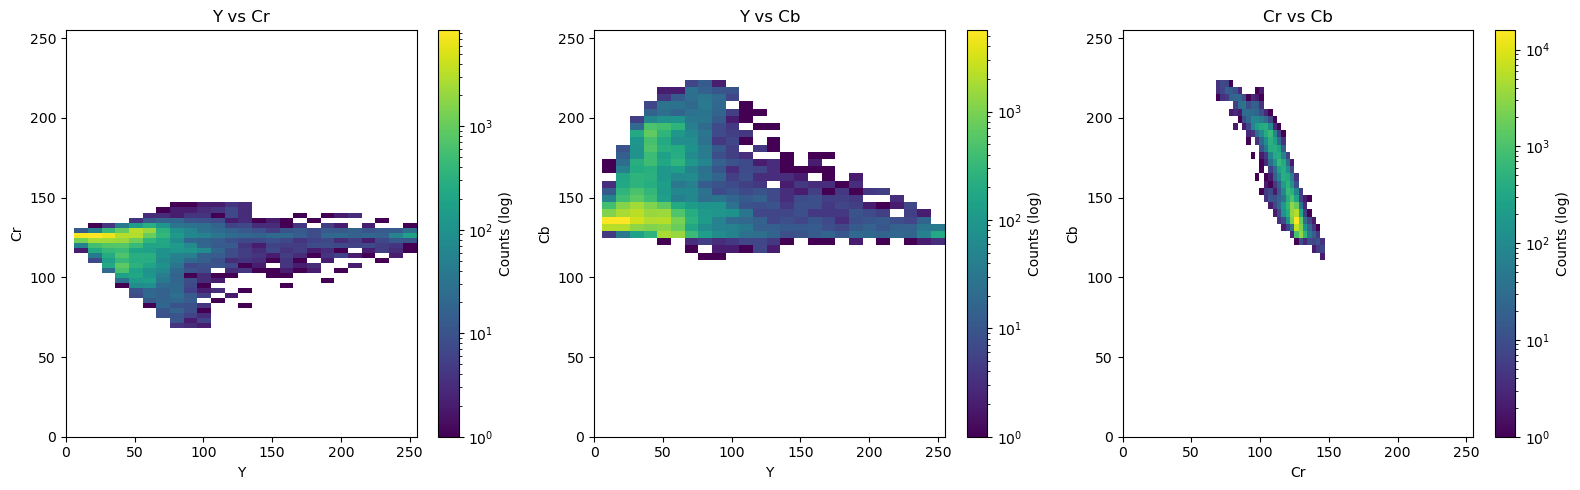

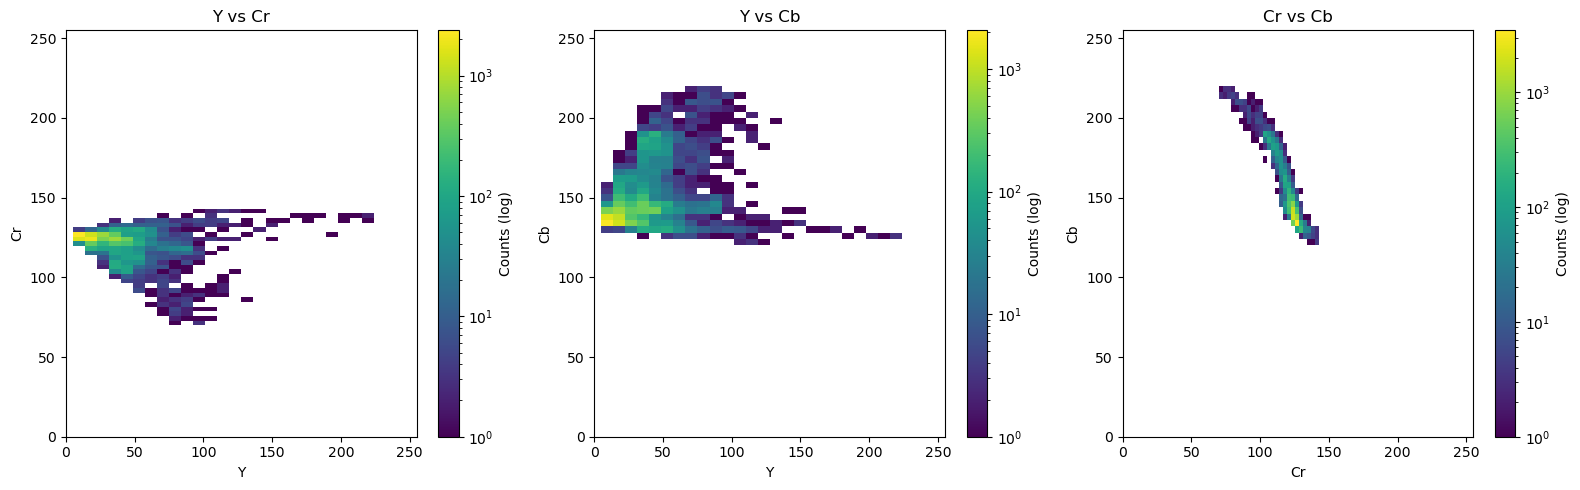

In [23]:
analyze_color_space(
    image_paths,
    color_code=cv.COLOR_BGR2YCrCb,
    names=("Y", "Cr", "Cb"),
    limits=((0, 255), (0, 255), (0, 255)),
)
analyze_color_space(
    image_paths2,
    color_code=cv.COLOR_BGR2YCrCb,
    names=("Y", "Cr", "Cb"),
    limits=((0, 255), (0, 255), (0, 255)),
)

**Con ejemplos mas pequenos**

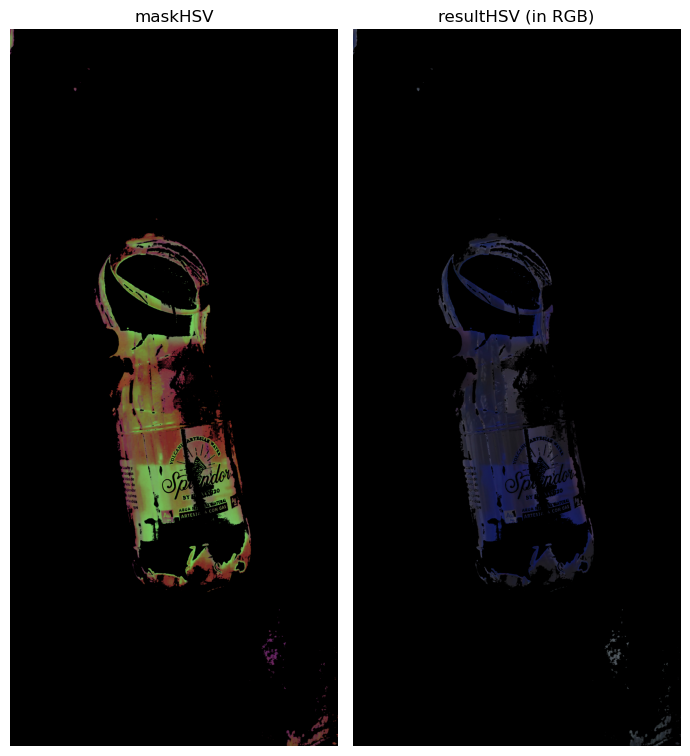

In [24]:
hsv_center = [115, 150, 50]
thresh_hsv = [30, 115, 50] 

minHSV = np.array([
    max(0, hsv_center[0] - thresh_hsv[0]),
    max(0, hsv_center[1] - thresh_hsv[1]),
    max(0, hsv_center[2] - thresh_hsv[2])
])

maxHSV = np.array([
    min(179, hsv_center[0] + thresh_hsv[0]),
    min(255, hsv_center[1] + thresh_hsv[1]),
    min(255, hsv_center[2] + thresh_hsv[2])
])

maskHSV = cv.inRange(brightHSV, minHSV, maxHSV)
resultHSV = cv.bitwise_and(brightHSV, brightHSV, mask=maskHSV)

resultRGB = cv.cvtColor(resultHSV, cv.COLOR_HSV2RGB)

plt.figure(figsize=(7, 8))

plt.subplot(1, 2, 1)
plt.imshow(resultHSV)
plt.title('maskHSV')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(resultRGB)
plt.title('resultHSV (in RGB)')
plt.axis('off')

plt.tight_layout()
plt.show()

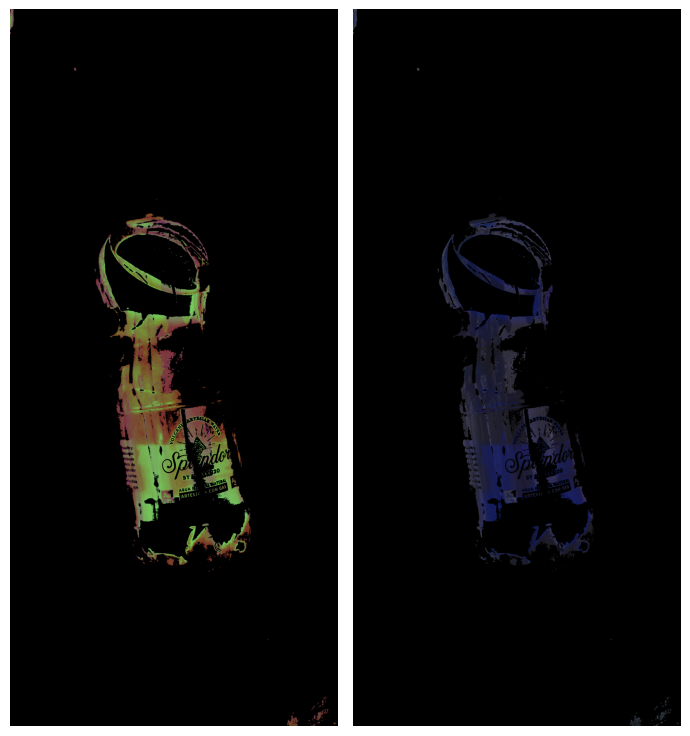

In [26]:
hsv_center = [115, 150, 50]
thresh_hsv = [15, 105, 50]

hsv = np.array(hsv_center)

minHSV = np.array([
    max(0, hsv_center[0] - thresh_hsv[0]),
    max(0, hsv_center[1] - thresh_hsv[1]),
    max(0, hsv_center[2] - thresh_hsv[2])
])

maxHSV = np.array([
    min(179, hsv_center[0] + thresh_hsv[0]),
    min(255, hsv_center[1] + thresh_hsv[1]),
    min(255, hsv_center[2] + thresh_hsv[2])
])

maskHSV = cv.inRange(brightHSV, minHSV, maxHSV)

resultHSV = cv.bitwise_and(brightHSV, brightHSV, mask=maskHSV)
resultRGB = cv.cvtColor(resultHSV, cv.COLOR_HSV2RGB)

plt.figure(figsize=(7, 8))

plt.subplot(1, 2, 1)
plt.imshow(resultHSV)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(resultRGB)
plt.axis('off')

plt.tight_layout()
plt.show()

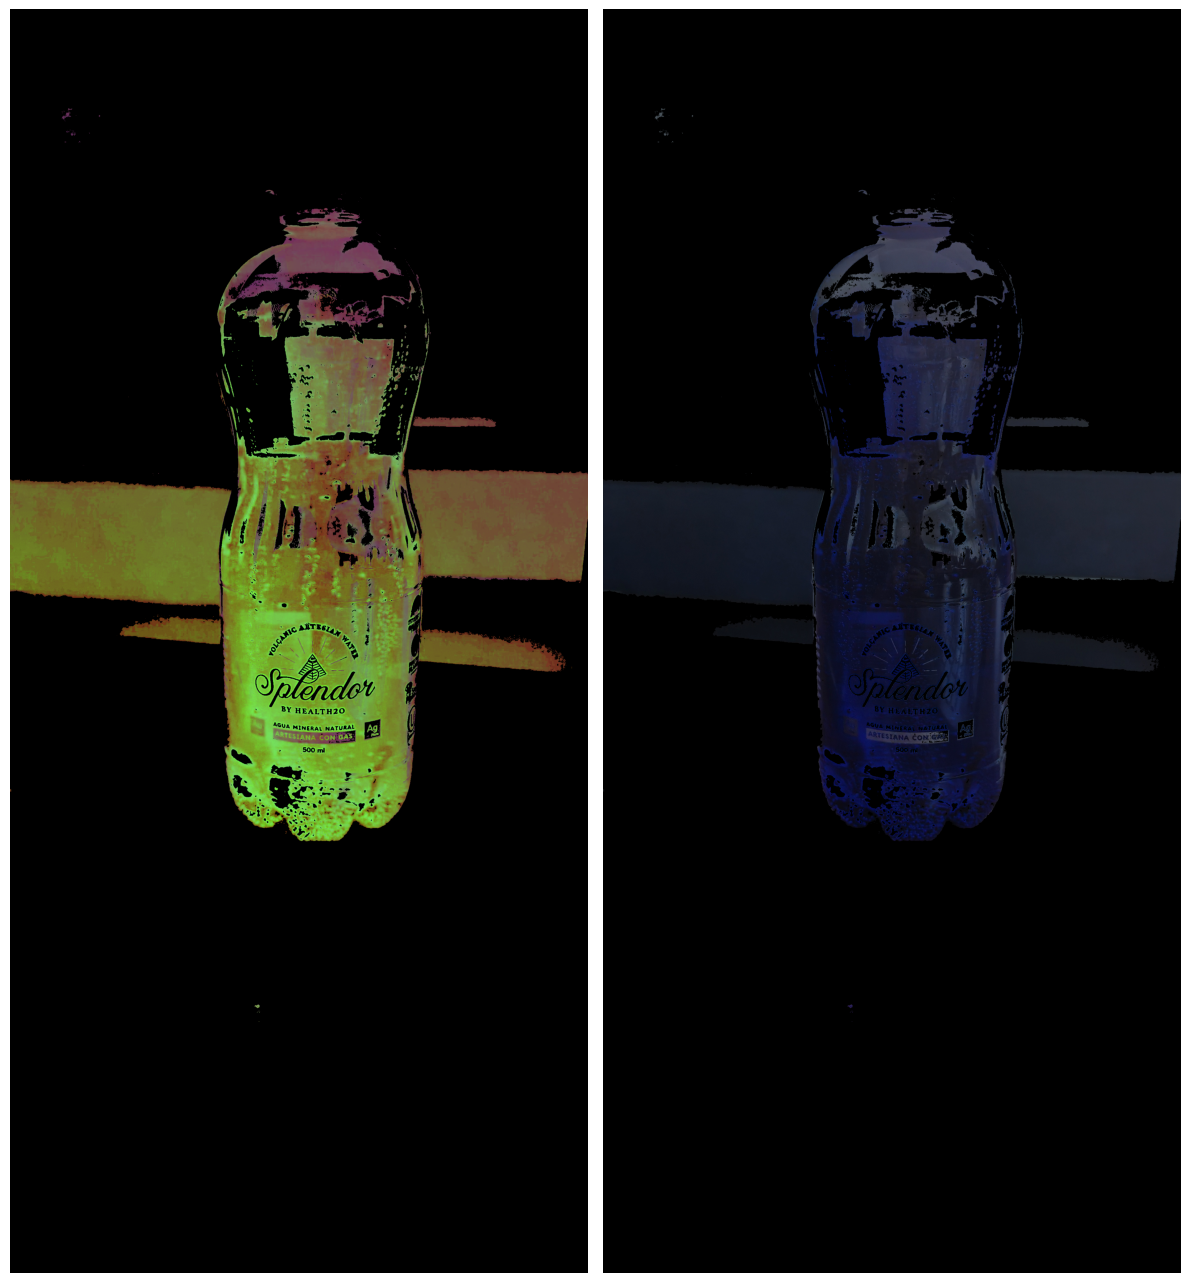

In [28]:
hsv_center = [115, 150, 50]
thresh_hsv = [15, 105, 50]

hsv = np.array(hsv_center)

minHSV = np.array([
    max(0, hsv_center[0] - thresh_hsv[0]),
    max(0, hsv_center[1] - thresh_hsv[1]),
    max(0, hsv_center[2] - thresh_hsv[2])
])

maxHSV = np.array([
    min(179, hsv_center[0] + thresh_hsv[0]),
    min(255, hsv_center[1] + thresh_hsv[1]),
    min(255, hsv_center[2] + thresh_hsv[2])
])

maskHSV = cv.inRange(darkHSV, minHSV, maxHSV)

resultHSV = cv.bitwise_and(darkHSV, darkHSV, mask=maskHSV)
resultRGB = cv.cvtColor(resultHSV, cv.COLOR_HSV2RGB)

plt.figure(figsize=(12, 14))

plt.subplot(1, 2, 1)
plt.imshow(resultHSV)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(resultRGB)
plt.axis('off')

plt.tight_layout()
plt.show()